<a href="https://colab.research.google.com/github/haider6tahir/Machine-Learning-Journey/blob/main/ANNasBinaryClassifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

In [ ]:
import pandas as pd

df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])
df["Target"] = y

df.head()

,Feature_1,Feature_2,Target
0,-0.111667,0.520224,1
1,1.142650,-0.342577,1
2,0.795558,-0.011442,1
3,0.111827,-0.551932,1
4,-0.816466,0.543996,0


X shape: (1000, 2)
y shape: (1000,)


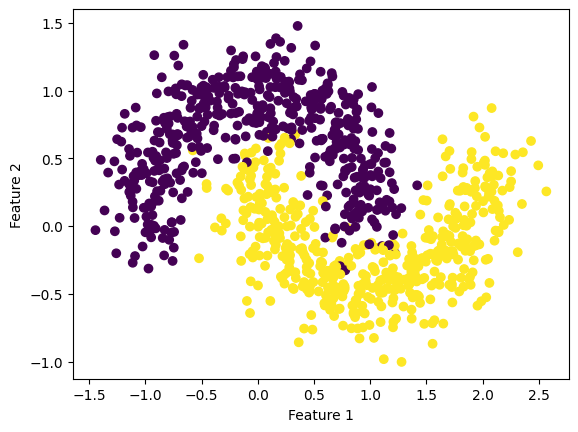

In [ ]:
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)


plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(
    y_train.reshape(-1, 1), dtype=torch.float32
)
y_test = torch.tensor(
    y_test.reshape(-1, 1), dtype=torch.float32
)

print(X_train.shape)
print(y_train.shape)

torch.Size([800, 2])
torch.Size([800, 1])


In [ ]:
# Building the ANN
class BinaryANN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)


model = BinaryANN()

print(model)

BinaryANN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.01
)

# criterion measures prediction error.



# optimizer updates the weights and biases.



# lr=0.01 is the learning rate.

In [ ]:
# Model(X_train) performs the forward pass.

# criterion(...) calculates the loss.
# optimizer.zero_grad() clears old gradients.
# loss.backward() calculates gradients using backpropagation.
# optimizer.step() updates the parameters.

epochs = 200

for epoch in range(epochs):

    # Forward propagation
    logits = model(X_train)

    # Calculate loss
    loss = criterion(logits, y_train)

    # Clear previous gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update weights and biases
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [20/200], Loss: 0.0641
Epoch [40/200], Loss: 0.0633
Epoch [60/200], Loss: 0.0628
Epoch [80/200], Loss: 0.0623
Epoch [100/200], Loss: 0.0618
Epoch [120/200], Loss: 0.0611
Epoch [140/200], Loss: 0.0607
Epoch [160/200], Loss: 0.0603
Epoch [180/200], Loss: 0.0599
Epoch [200/200], Loss: 0.0595


In [ ]:
# Make binary predictions

model.eval()

with torch.no_grad():
    logits = model(X_test)

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= 0.5).float()

accuracy = accuracy_score(
    y_test.numpy(),
    predictions.numpy()
)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 99.50%


In [ ]:
print("Actual labels:     ", y_test[:10].squeeze().numpy())
print("Predicted labels:  ", predictions[:10].squeeze().numpy())
print("Predicted probs:   ", probabilities[:10].squeeze().numpy().round(3))

Actual labels:      [1. 0. 0. 0. 1. 1. 1. 1. 0. 0.]
Predicted labels:   [1. 0. 0. 0. 1. 1. 1. 1. 0. 0.]
Predicted probs:    [0.999 0.    0.    0.    0.995 0.999 1.    1.    0.002 0.04 ]


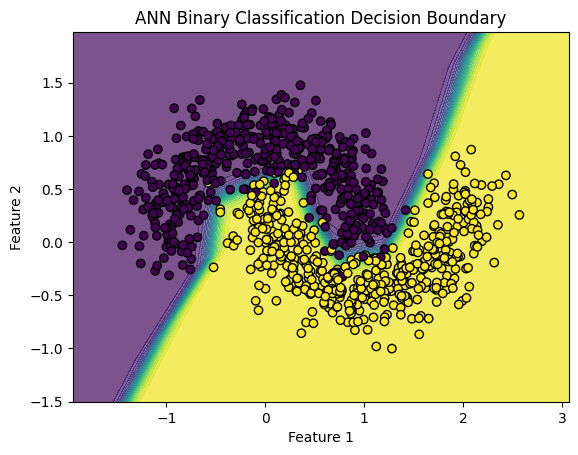

In [ ]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)

grid_tensor = torch.tensor(
    grid_scaled, dtype=torch.float32
)

model.eval()

with torch.no_grad():
    probs = torch.sigmoid(model(grid_tensor))
    Z = probs.reshape(xx.shape).numpy()

plt.contourf(xx, yy, Z, levels=20, alpha=0.7)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="black")
plt.title("ANN Binary Classification Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()